### Building chatbot using the langgraph

In [5]:
from typing import Annotated
from typing_extensions import TypedDict


from langgraph.graph import StateGraph, START,END
from langgraph.graph.message import add_messages


In [6]:
class State(TypedDict):
    messages:Annotated[list,add_messages]

graph_builder = StateGraph(State)


In [7]:
graph_builder

In [8]:
import os
from dotenv import load_dotenv
load_dotenv()


True

In [9]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm = ChatGroq(model ="qwen/qwen3.8-27b")


In [10]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, client=<groq.resources.chat.completions.Completions object at 0x777b580a0590>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x777b580a12b0>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [11]:
##Functionality of the node
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [12]:
graph_builder=StateGraph(State)
graph_builder.add_node("chatbot",chatbot)
graph_builder.add_edge(START,"chatbot")
graph_builder.add_edge("chatbot",END)
graph =graph_builder.compile()

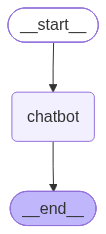

In [13]:
graph

In [14]:
response =graph.invoke({"messages":"hi"})

In [15]:
response["messages"][-1].content

'Hi there! How can I help you today?'

In [16]:
for event in graph.stream({"messages":"Hi How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

I'm doing well, thank you for asking! How can I help you today?


### Chatbot with the tool

In [17]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results =2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

In [51]:
## custom function
def multiply(a:int, b:int) -> int:
    """Multiply a and b

    Args:
      a (int): first int
      b (int): second int

    Returns:
      int: output int
    """
    return a*b
    

In [52]:
tools =[tool,multiply]

In [53]:
llm_tools = llm.bind_tools(tools)

In [54]:
llm_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, client=<groq.resources.chat.completions.Completions object at 0x777b580a0590>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x777b580a12b0>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted results. Useful for when you need to answer questions about current events. It not only retrieves URLs and snippets, but offers advanced search depths, domain management, time range filters, and image search, this tool delivers real-time, accurate, and citation-backed results.Input should be a search query.', 'parameters': {'properties': {'query': {'description': 'Search query to look up', 'type': 'string'}, 'include_domains': {'anyOf': [{'items': {'type': 'string'}, 't

In [55]:
## state graph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

#defination of the node

def tool_calling_llm(state:State):
    return {"messages":[llm_tools.invoke(state["messages"])]}

#creaing the graph

builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

#adding the edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)
builder.add_edge("tools",END)

graph = builder.compile()


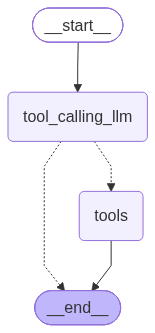

In [56]:
graph

In [45]:
response =graph.invoke({"messages":"what is the recent ai news"})

In [46]:
response["messages"][-1]

ToolMessage(content='{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.npr.org/2026/09/18/nx-s1-5971154/open-ai-anthropic-news-research-takeover", "title": "The latest on AI panic — and whether it\'s justified : Short Wave : NPR", "content": "AI is in the news again – for its potential to end civilization. A researcher at Anthropic resigned very publicly last week, citing concerns about the accelerating capabilities of AI and what he called \\"irresponsible\\" behavior from major AI companies Anthropic and OpenAI. Following his resignation, the leaders of both companies called for an internationally cooperative, industry-wide slowdown on advanced AI development. And Wednesday, OpenAI disclosed six more incidents of \\"unexpected or [...] The latest on AI panic — and whether it\'s justified : Short Wave AI is in the news again – for its potential to end civilization. A researcher at Anthropic resigned very publicly la

In [49]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

what is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (3080xpape)
 Call ID: 3080xpape
  Args:
    query: recent AI news
    time_range: month
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.npr.org/2026/09/18/nx-s1-5971154/open-ai-anthropic-news-research-takeover", "title": "The latest on AI panic — and whether it's justified : Short Wave : NPR", "content": "AI is in the news again – for its potential to end civilization. A researcher at Anthropic resigned very publicly last week, citing concerns about the accelerating capabilities of AI and what he called \"irresponsible\" behavior from major AI companies Anthropic and OpenAI. Following 

In [57]:
response =graph.invoke({"messages":"what is the 2 multiply by 3"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

what is the 2 multiply by 3
================================== Ai Message ==================================
Tool Calls:
  multiply (ks61q4tzz)
 Call ID: ks61q4tzz
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: multiply

6


In [58]:
response =graph.invoke({"messages":"what is the 2 multiply by 3 and multiply 10"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

what is the 2 multiply by 3 and multiply 10
================================== Ai Message ==================================

I'll calculate both multiplications for you.
Tool Calls:
  multiply (0d2j2723s)
 Call ID: 0d2j2723s
  Args:
    a: 2
    b: 3
  multiply (hxxy1bf8g)
 Call ID: hxxy1bf8g
  Args:
    a: 2
    b: 10
================================= Tool Message =================================
Name: multiply

6
================================= Tool Message =================================
Name: multiply

20


### React Agent Archiecute

In [59]:
## state graph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

#defination of the node

def tool_calling_llm(state:State):
    return {"messages":[llm_tools.invoke(state["messages"])]}

#creaing the graph

builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

#adding the edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

graph = builder.compile()

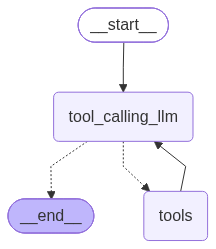

In [61]:
graph

In [62]:
response =graph.invoke({"messages":"tell me about the lastest update in AI also please multiply 2 by 3"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

tell me about the lastest update in AI also please multiply 2 by 3
================================== Ai Message ==================================

I'll help with both. Let me search for the latest AI updates and calculate the multiplication.
Tool Calls:
  tavily_search (2gw0pn9pq)
 Call ID: 2gw0pn9pq
  Args:
    query: latest AI updates news
    time_range: month
  multiply (ee3zhrrqg)
 Call ID: ee3zhrrqg
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI updates news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-september-2026", "title": "The latest AI news we announced in September 2026", "content": "Google just released a bunch of new AI updates, including the powerful Gemini 4 Argon model for solvin

### Assing Memory in Agentic Graph

In [82]:
## state graph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver


memory = MemorySaver()
#defination of the node

def tool_calling_llm(state:State):
    return {"messages":[llm_tools.invoke(state["messages"])]}

#creaing the graph

builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

#adding the edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

graph = builder.compile(checkpointer=memory)

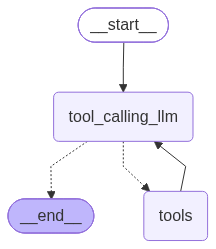

In [83]:
graph

In [84]:
config ={"configurable":{"thread_id":"1"}}
respone =graph.invoke({"messages":"Hi my name is sahil"},config=config)
response

{'messages': [HumanMessage(content='hello my name is Sahil how are you?', additional_kwargs={}, response_metadata={}, id='9d0601d6-994a-4a53-9a80-b097aa376299'),
  AIMessage(content="Hello Sahil! I'm doing well, thank you for asking. How can I help you today?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 22, 'prompt_tokens': 1915, 'total_tokens': 1937, 'completion_time': 0.041945459, 'completion_tokens_details': None, 'prompt_time': 0.131963209, 'prompt_tokens_details': None, 'queue_time': 0.045996312, 'total_time': 0.173908668}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12739-44a4-7a91-a863-82d3df3d1ea8-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1915, 'output_tokens': 22, 'total_tokens': 1937})]}

In [85]:
response["messages"][-1].content

"Hello Sahil! I'm doing well, thank you for asking. How can I help you today?"

In [86]:
respone =graph.invoke({"messages":"do you remember my name"},config=config)
response["messages"][-1].content

"Hello Sahil! I'm doing well, thank you for asking. How can I help you today?"

### Streaming

In [87]:
from langgraph.checkpoint.memory import MemorySaver


memory = MemorySaver()

In [88]:
def superbot(state:State):
    return {"messages":[llm_tools.invoke(state["messages"])]}

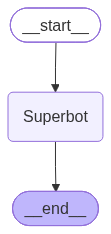

In [89]:
graph = StateGraph(State)

graph.add_node("Superbot",superbot)
graph.add_edge(START,"Superbot")
graph.add_edge("Superbot",END)

graph_builder = graph.compile(checkpointer=memory)

graph_builder

In [91]:
config ={"configurable":{"thread_id":"1"}}
respone =graph_builder.invoke({"messages":"Hi my name is sahil and I like cricket"},config)

In [92]:
response

{'messages': [HumanMessage(content='hello my name is Sahil how are you?', additional_kwargs={}, response_metadata={}, id='9d0601d6-994a-4a53-9a80-b097aa376299'),
  AIMessage(content="Hello Sahil! I'm doing well, thank you for asking. How can I help you today?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 22, 'prompt_tokens': 1915, 'total_tokens': 1937, 'completion_time': 0.041945459, 'completion_tokens_details': None, 'prompt_time': 0.131963209, 'prompt_tokens_details': None, 'queue_time': 0.045996312, 'total_time': 0.173908668}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12739-44a4-7a91-a863-82d3df3d1ea8-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1915, 'output_tokens': 22, 'total_tokens': 1937})]}

In [100]:
config ={"configurable":{"thread_id":"2"}}
for chunk in graph_builder.stream({"messages":"Hi my name is sahil and I like cricket"},config, stream_mode="updates"):
    print(chunk)

{'Superbot': {'messages': [AIMessage(content='Hi Sahil! It’s great to meet you. Since you love cricket, I’m curious:\n\n*   **Who is your favorite player?** (e.g., Virat Kohli, Sachin Tendulkar, Ben Stokes, etc.)\n*   **Do you prefer Tests, ODIs, or T20s?**\n*   **Which team do you support?**\n\nIf you’d like, I can also fetch the **latest cricket scores**, **news**, or **player stats** for you. Just let me know what you’re interested in! 🏏', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 119, 'prompt_tokens': 2120, 'total_tokens': 2239, 'completion_time': 0.239168733, 'completion_tokens_details': None, 'prompt_time': 0.146235207, 'prompt_tokens_details': None, 'queue_time': 0.046543112, 'total_time': 0.38540394}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12752-283d-7a01-a2ac-ec4395bed59b-0', tool_calls=[], inval

In [99]:
for chunk in graph_builder.stream({"messages":"Hi my name is sahil and I like cricket"},config, stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi my name is sahil and I like cricket', additional_kwargs={}, response_metadata={}, id='2c91c7dc-28cd-479b-90ff-86ac0f41255a'), AIMessage(content="Hi Sahil! Nice to meet you. Cricket is a fantastic sport — it has such rich history, strategy, and exciting moments.\n\nAre you a fan of any particular team or player? Or is there anything specific about cricket you'd like to chat about (like recent matches, rules, or stats)?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 63, 'prompt_tokens': 1915, 'total_tokens': 1978, 'completion_time': 0.120013546, 'completion_tokens_details': None, 'prompt_time': 0.13595969, 'prompt_tokens_details': None, 'queue_time': 0.047785669, 'total_time': 0.255973236}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1274f-22f8-7323-bc90-21257caa910e-0', tool_

In [102]:
config ={"configurable":{"thread_id":"3"}}
async for event in graph_builder.astream_events({"messages":"Hi my name is sahil and I like cricket"},config, version="v2"):
    print(chunk)

{'Superbot': {'messages': [AIMessage(content='Hi Sahil! It’s great to meet you. Since you love cricket, I’m curious:\n\n*   **Who is your favorite player?** (e.g., Virat Kohli, Sachin Tendulkar, Ben Stokes, etc.)\n*   **Do you prefer Tests, ODIs, or T20s?**\n*   **Which team do you support?**\n\nIf you’d like, I can also fetch the **latest cricket scores**, **news**, or **player stats** for you. Just let me know what you’re interested in! 🏏', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 119, 'prompt_tokens': 2120, 'total_tokens': 2239, 'completion_time': 0.239168733, 'completion_tokens_details': None, 'prompt_time': 0.146235207, 'prompt_tokens_details': None, 'queue_time': 0.046543112, 'total_time': 0.38540394}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12752-283d-7a01-a2ac-ec4395bed59b-0', tool_calls=[], inval